In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import seaborn as sns
sns.set_palette('colorblind')
from matplotlib.pyplot import tight_layout
# ##SETTING PARAMS FOR MATPLOTLIB FIGURES
plt.rcParams.update({"figure.figsize": (6, 6),
                 "axes.facecolor": "white",
                 "axes.edgecolor": "black"})
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=sns.color_palette('colorblind'))
##set font size
font = {'family': 'sans-serif',
       'weight': 'normal',
       'size': 14}
plt.rc('font', **font)
# ##PANDAS PLOTTING
pd.plotting.register_matplotlib_converters()


### Step 1: save environment file

In [2]:
!conda env export > quasi_poisson_environment.yml

### Step 2: import modules


In [3]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import numpy as np
import pandas as pd
import matplotlib as plt
import glob
import os
import xml.etree.ElementTree as ET
from datetime import datetime, timezone
from tqdm import tqdm
import codecs
import csv
import openpyxl
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch

# For inline plots in Jupyter
%matplotlib inline

### Step 2 : Import files

In [4]:
data_directory_weather = "/home/paulharford/college/project/project_data/processed/WEATHERED_warnings_2014-2023_cleaned_v4.csv"
data_directory_ihfd = "/home/paulharford/college/project/project_data/processed/WEATHERED_ihfd_clean_v2.csv"
data_directory_census = "/home/paulharford/college/project/project_data/processed/WEATHERED_census_pop_age_grp_gender_region.csv"
full_path_ihfd = os.path.abspath(data_directory_ihfd)
full_path_weather = os.path.abspath(data_directory_weather)
full_path_census = os.path.abspath(data_directory_census)

In [5]:
df_ihfd = pd.read_csv(full_path_ihfd)
df_weather = pd.read_csv(full_path_weather)
df_census = pd.read_csv(full_path_census)

### Step 3: Create full dates range for 2014 to 2023 to merge with datasets, this will be used to provide days where there are no hip fratcure incidents 

In [6]:
##set date range
regions = df_weather['region'].unique()
min_date = df_weather['date'].min()
max_date = df_weather['date'].max()

In [7]:
##set date_time type and create date variable
df_weather["Valid From"] = pd.to_datetime(df_weather["Valid From"])
df_weather["date"] = df_weather["Valid From"].dt.date
df_weather["date"] = pd.to_datetime(df_weather["date"])
df_weather["Valid To"] = pd.to_datetime(df_weather["Valid To"])


In [8]:
##create all dates for all years to merge with datasets so we can have days with and without events 
all_dates = pd.date_range(start=min_date, end=max_date, freq='D')
multi_index = pd.MultiIndex.from_product([regions, all_dates], names=['region', 'date'])
df_region_date = pd.DataFrame(index=multi_index).reset_index()


In [9]:
##copy full date range for hip and weather data
df_region_date_hip = df_region_date.copy()

In [10]:
df_region_date_weather = df_region_date.copy()

In [11]:
df_region_date_census = df_region_date.copy()

### Step 4: Weather data

In [12]:
df_weather.head(10)

,Issue Time,Valid From,Valid To,Warning Colour,Warning Element,Warning Text,Clare,Cork,Kerry,Limerick,...,warning_severity,weather_type,Duration_hours,date,region,counties_in_region,weather_event_density,county_weight,affected_counties_count,affected_counties_proportion
0,2023-11-12 15:00:00+00:00,2023-11-13 05:00:00+00:00,2023-11-13 07:00:00+00:00,Red,Wind,Extremely gusty on Sunday night and Monday due...,0,0,0,0,...,Red,Wind warning,2.000000,2023-11-13,HSE Dublin and Midlands,7,1,0.142857,0,0.0
1,2023-11-12 15:00:00+00:00,2023-11-13 05:00:00+00:00,2023-11-13 07:00:00+00:00,Red,Wind,Extremely gusty on Sunday night and Monday due...,0,0,0,0,...,Red,Wind warning,2.000000,2023-11-13,HSE Dublin and South East,7,1,0.142857,0,0.0
2,2023-11-12 15:00:00+00:00,2023-11-13 05:00:00+00:00,2023-11-13 07:00:00+00:00,Red,Wind,Extremely gusty on Sunday night and Monday due...,0,0,0,0,...,Red,Wind warning,2.000000,2023-11-13,HSE Mid West,3,1,0.333333,0,0.0
3,2023-11-12 15:00:00+00:00,2023-11-13 05:00:00+00:00,2023-11-13 07:00:00+00:00,Red,Wind,Extremely gusty on Sunday night and Monday due...,0,0,0,0,...,Red,Wind warning,2.000000,2023-11-13,HSE South West,2,1,0.500000,0,0.0
4,2023-11-12 15:00:00+00:00,2023-11-13 05:00:00+00:00,2023-11-13 07:00:00+00:00,Red,Wind,Extremely gusty on Sunday night and Monday due...,0,0,0,0,...,Red,Wind warning,2.000000,2023-11-13,HSE West and North West,6,1,0.166667,0,0.0
5,2023-11-12 15:00:00+00:00,2023-11-13 03:00:00+00:00,2023-11-13 05:00:00+00:00,Red,Wind,Extremely gusty on Sunday night and early Mond...,0,0,0,0,...,Red,Wind warning,2.000000,2023-11-13,HSE Dublin and North East,5,1,0.200000,0,0.0
6,2021-12-07 12:05:59+00:00,2021-12-07 12:05:39+00:00,2021-12-07 21:00:00+00:00,Red,Red Wind,Storm Barra: Southwesterly winds later veering...,0,1,1,0,...,Red,Wind warning,8.905833,2021-12-07,HSE South West,2,1,0.500000,2,1.0
7,2017-10-16 16:02:38+00:00,2017-10-16 16:00:00+00:00,2017-10-17 01:00:00+00:00,Red,Wind,"Latest UpdateStorm Ophelia (Ex hurricane), sit...",1,1,1,1,...,Red,Wind warning,9.000000,2017-10-16,HSE West and North West,6,1,0.166667,6,1.0
8,2015-01-14 14:00:00+00:00,2015-01-14 21:00:00+00:00,2015-01-15 12:00:00+00:00,Red,Wind,Wind gusts 130 to 150km/h possible.High onshor...,1,0,1,1,...,Red,Wind warning,15.000000,2015-01-14,HSE South West,2,1,0.500000,1,0.5
9,2015-01-14 14:00:00+00:00,2015-01-14 21:00:00+00:00,2015-01-15 12:00:00+00:00,Red,Wind,Wind gusts 130 to 150km/h possible.High onshor...,1,0,1,1,...,Red,Wind warning,15.000000,2015-01-14,HSE West and North West,6,1,0.166667,3,0.5


### Step 4.1: Map weather severtiy to numeric value and aggregate weather data

In [13]:
##create a numerical mapping of the weather severity
severity_mapping = {
    'Yellow': 1,
    'Orange': 2,
    'Red': 3
}

df_weather['warning_severity_numeric'] = df_weather['warning_severity'].map(severity_mapping)

In [14]:
def aggregate_weather_data(df_weather, keep_columns=None):
    """
    Aggregate weather data by region, date, weather_type, and warning_severity while
    keeping specified columns.
    
    Args:
        df_weather: DataFrame containing weather data
        keep_columns: List of additional columns to preserve (beyond the groupby columns)
        
    Returns:
        Aggregated DF with one row per unique region-date-weather_type-warning_severity combination
    """
    # Define default columns to keep
    if keep_columns is None:
        keep_columns = [
            'counties_in_region', 	
            'county_weight'	
         ]
    
    # Define all columns to group by
    group_cols = ['region', 'date', 'warning_phenomenon', 'warning_severity']
    
    # Define aggregation functions for numeric and other columns
    agg_dict = {
        'warning_severity_numeric': 'max'
    }
    
    # Add aggregation functions 
    for col in keep_columns:
        if col in df_weather.columns:
            # For string columns, take the first value 
            if df_weather[col].dtype == 'object':
                agg_dict[col] = 'first'
            # For boolean or int lags
            elif df_weather[col].dtype in ['bool', 'int64', 'int32']:
                agg_dict[col] = 'max'
            # For numeric columns, take the max
            elif pd.api.types.is_numeric_dtype(df_weather[col]):
                agg_dict[col] = 'max'
            # For datetime columns
            elif pd.api.types.is_datetime64_dtype(df_weather[col]):
                agg_dict[col] = 'max'
            # Default to first value for any other types
            else:
                agg_dict[col] = 'first'
    
    # Group by the specified columns and aggregate
    weather_agg = df_weather.groupby(group_cols, as_index=False).agg(agg_dict)
    
    # Add the weather flag column to indicate there was an adverse wetaher event on that date 
    weather_agg['weather_event'] = 1
    
    return weather_agg

In [15]:
weather_agg = aggregate_weather_data(df_weather)

In [16]:
weather_agg.head()

,region,date,warning_phenomenon,warning_severity,warning_severity_numeric,counties_in_region,county_weight,weather_event
0,HSE Dublin and Midlands,2014-01-02,Wind,Yellow,1,7,0.142857,1
1,HSE Dublin and Midlands,2014-01-03,Wind,Yellow,1,7,0.142857,1
2,HSE Dublin and Midlands,2014-01-04,Snow_Ice,Yellow,1,7,0.142857,1
3,HSE Dublin and Midlands,2014-01-05,Wind,Yellow,1,7,0.142857,1
4,HSE Dublin and Midlands,2014-01-06,Wind,Orange,2,7,0.142857,1


### Step 4.2: Merge aggregated weather data with all date ranges so we have alldates with or without adverse weather events. 

In [17]:
df_weather_final = pd.merge(
    df_region_date_weather,
    weather_agg,               
    on=['region', 'date'],    
    how='left'            
)


### Step 4.3: Resolve any missing values after merge and aggregation steps

In [18]:
##after joining weather data to full date range there and NaN values - expected as not all days have weather events
df_weather_final['warning_severity_numeric'] = df_weather_final['warning_severity_numeric'].fillna(0)

In [19]:
df_weather_final['warning_phenomenon'] = df_weather_final['warning_phenomenon'].fillna('no_weather_type')

In [20]:
df_weather_final['warning_severity'] = df_weather_final['warning_severity'].fillna('no_weather_severity')

### Step 4.4: Add county count and county weight as not all regions have the same number of counties.

In [21]:
# HSE region mapping.
hse_regions = {
    'HSE Dublin and North East': ['Cavan', 'Monaghan', 'Louth', 'Meath', 'Dublin'],
    'HSE Dublin and Midlands': ['Kildare', 'Wicklow', 'Laois', 'Offaly', 'Longford', 'Westmeath', 'Dublin'],
    'HSE Dublin and South East': ['Carlow', 'Kilkenny', 'Tipperary', 'Waterford', 'Wexford', 'Wicklow', 'Dublin'],
    'HSE Mid West': ['Clare', 'Limerick', 'Tipperary'],
    'HSE South West': ['Cork', 'Kerry'],
    'HSE West and North West': ['Donegal', 'Sligo', 'Leitrim', 'Mayo', 'Galway', 'Roscommon']
}

# List of all county columns
county_cols = [
    "Clare", "Cork", "Kerry", "Limerick", "Tipperary", "Waterford",
    "Carlow", "Dublin", "Kildare", "Kilkenny", "Laois", "Longford",
    "Louth", "Meath", "Offaly", "Westmeath", "Wexford", "Wicklow",
    "Cavan", "Donegal", "Monaghan", "Galway", "Leitrim", "Mayo",
    "Roscommon", "Sligo"
]


In [22]:
if df_weather_final['counties_in_region'].isna().any() or df_weather_final['county_weight'].isna().any():
    # Fill counties_in_region with values from your mapping
    df_weather_final['counties_in_region'] = df_weather_final['region'].map(
        {region: len(counties) for region, counties in hse_regions.items()}
    )
    
    # Recalculate county_weight 
    df_weather_final['county_weight'] = 1 / df_weather_final['counties_in_region']

In [23]:
df_weather_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22511 entries, 0 to 22510
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   region                    22511 non-null  object        
 1   date                      22511 non-null  datetime64[ns]
 2   warning_phenomenon        22511 non-null  object        
 3   warning_severity          22511 non-null  object        
 4   warning_severity_numeric  22511 non-null  float64       
 5   counties_in_region        22511 non-null  int64         
 6   county_weight             22511 non-null  float64       
 7   weather_event             4571 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(3)
memory usage: 1.4+ MB


In [24]:
df_weather_final['weather_event'] = df_weather_final['weather_event'].fillna(0)

### Step 4.5: Final weather dataset has per region the severity, if there was a weather event or not, the numer of counties the evenet was in and the weather type

In [25]:
df_weather_final.head(10)

,region,date,warning_phenomenon,warning_severity,warning_severity_numeric,counties_in_region,county_weight,weather_event
0,HSE Dublin and Midlands,2014-01-02,Wind,Yellow,1.0,7,0.142857,1.0
1,HSE Dublin and Midlands,2014-01-03,Wind,Yellow,1.0,7,0.142857,1.0
2,HSE Dublin and Midlands,2014-01-04,Snow_Ice,Yellow,1.0,7,0.142857,1.0
3,HSE Dublin and Midlands,2014-01-05,Wind,Yellow,1.0,7,0.142857,1.0
4,HSE Dublin and Midlands,2014-01-06,Wind,Orange,2.0,7,0.142857,1.0
5,HSE Dublin and Midlands,2014-01-07,no_weather_type,no_weather_severity,0.0,7,0.142857,0.0
6,HSE Dublin and Midlands,2014-01-08,no_weather_type,no_weather_severity,0.0,7,0.142857,0.0
7,HSE Dublin and Midlands,2014-01-09,no_weather_type,no_weather_severity,0.0,7,0.142857,0.0
8,HSE Dublin and Midlands,2014-01-10,no_weather_type,no_weather_severity,0.0,7,0.142857,0.0
9,HSE Dublin and Midlands,2014-01-11,no_weather_type,no_weather_severity,0.0,7,0.142857,0.0


### Step 5: Irish hip fracture data

### Step 5.1: Change "Adm_First_Pres_Hosp_DateTime" to date as "date is one of our common features across datasets"

In [26]:
df_ihfd["Adm_First_Pres_Hosp_DateTime"] = pd.to_datetime(df_ihfd["Adm_First_Pres_Hosp_DateTime"])
df_ihfd["date"] = df_ihfd["Adm_First_Pres_Hosp_DateTime"].dt.date
df_ihfd["date"] = pd.to_datetime(df_ihfd["date"])

### Step 5.2: Filter date range - 2014 to end of 2023

In [28]:
df_ihfd_filtered = df_ihfd[
    (df_ihfd['date'] >= '2014-01-01') & 
    (df_ihfd['date'] <= '2023-12-31').copy()
]

In [29]:
nan_counts = df_ihfd_filtered.isna().sum()
print(nan_counts)

region                          0
NOCA_TraumaPeriodDay            0
Adm_First_Pres_Hosp_DateTime    0
NOCA_FirstPresPeriodDay         0
age_group                       0
gender                          0
LOS                             0
Adm_Trauma_TYPE                 0
Adm_Ward_Type                   0
Adm_Pre_Frac_Indoor             0
Adm_PRE_Frac_Outdoor            0
Adm_Pre_Frac_Shop               0
Adm_Pre_Frac_Number             0
Adm_Fracture_Type               0
Adm_Pathological                0
Adm_Fragility                   0
Adm_Pre_OP_Med_Assess           0
Adm_Ger_Acute_Assess            0
Adm_Operation                   0
Adm_Asa_Grade                   0
Adm_Anaesthesia                 0
Adm_Surgery_Delay_Reason        0
Adm_Mobilised                   0
Adm_Pressure_Ulcers             0
Adm_Spec_Falls_Assess           0
Adm_Bone_Protect_Med            0
Adm_Multi_Rehab_Assess          0
date                            0
year                            0
dtype: int64


### Step 5.3: Check rates in my datset against teh NOCA report form 2022

In [30]:
# Count hip fractures by year for all regions
## sanity check to see what the numbers are in my dataset against the 2022 noca report- noca process may be done differently so 
# Filter for pecific years to check 
target_years = [2018, 2020, 2022]

# Create a date column with just the year
df_ihfd['year'] = pd.to_datetime(df_ihfd['date']).dt.year

# Get counts by year 
yearly_totals = df_ihfd[df_ihfd['year'].isin(target_years)].groupby('year').size().reset_index()
yearly_totals.columns = ['Year', 'Total Hip Fractures']

# Get counts by region and year
region_year_counts = df_ihfd[df_ihfd['year'].isin(target_years)].pivot_table(
    index='region', 
    columns='year', 
    values='date',  # Any column would work here since we're just counting
    aggfunc='count',
    fill_value=0
).reset_index()

# Add row for totals
totals_row = pd.DataFrame({
    'region': ['All Regions'],
    **{year: [yearly_totals[yearly_totals['Year']==year]['Total Hip Fractures'].values[0]] for year in target_years}
})

# Combine regional data with totals
final_counts = pd.concat([region_year_counts, totals_row], ignore_index=True)

# Display the results
print("Hip Fractures by Region and Year:\n")
print(final_counts)

# Compare with provided reference numbers
print("\nReference Counts:")
print(f"2018: 3751 | Your data: {yearly_totals[yearly_totals['Year']==2018]['Total Hip Fractures'].values[0]}")
print(f"2020: 3666 | Your data: {yearly_totals[yearly_totals['Year']==2020]['Total Hip Fractures'].values[0]}")
print(f"2022: 3909 | Your data: {yearly_totals[yearly_totals['Year']==2022]['Total Hip Fractures'].values[0]}")

Hip Fractures by Region and Year:

                      region  2018  2020  2022
0    HSE Dublin and Midlands   576   566   691
1  HSE Dublin and North East   819   790   980
2  HSE Dublin and South East   773   700   667
3               HSE Mid West   162   326   352
4             HSE South West   606   593   576
5    HSE West and North West   612   648   696
6                All Regions  3548  3623  3962

Reference Counts:
2018: 3751 | Your data: 3548
2020: 3666 | Your data: 3623
2022: 3909 | Your data: 3962


### Step 5.4: Aggregate hip data 

In [31]:
hip_agg = (
    df_ihfd_filtered
    .groupby(['region', 'date', 'age_group', 'gender'])
    .agg(
        hip_fracture_count=('date', 'count')
    )
    .reset_index()
)


In [32]:
hip_agg.head()


,region,date,age_group,gender,hip_fracture_count
0,HSE Dublin and Midlands,2014-01-02,65-69,Female,1
1,HSE Dublin and Midlands,2014-01-04,65-69,Female,1
2,HSE Dublin and Midlands,2014-01-04,80-84,Female,1
3,HSE Dublin and Midlands,2014-01-04,85 years and over,Female,2
4,HSE Dublin and Midlands,2014-01-06,65-69,Male,1


### Step 5.6: Merge date range df with hip data 

In [33]:
df_hip_final = pd.merge(
    df_region_date_hip,          # all region-date combos
    hip_agg,               
    on=['region', 'date'],   
    how='left'           
)

In [34]:
df_hip_final.head(15)

,region,date,age_group,gender,hip_fracture_count
0,HSE Dublin and Midlands,2014-01-02,65-69,Female,1.0
1,HSE Dublin and Midlands,2014-01-03,NaN,NaN,NaN
2,HSE Dublin and Midlands,2014-01-04,65-69,Female,1.0
3,HSE Dublin and Midlands,2014-01-04,80-84,Female,1.0
4,HSE Dublin and Midlands,2014-01-04,85 years and over,Female,2.0
5,HSE Dublin and Midlands,2014-01-05,NaN,NaN,NaN
6,HSE Dublin and Midlands,2014-01-06,65-69,Male,1.0
7,HSE Dublin and Midlands,2014-01-07,NaN,NaN,NaN
8,HSE Dublin and Midlands,2014-01-08,75-79,Female,1.0
9,HSE Dublin and Midlands,2014-01-09,85 years and over,Female,1.0


### Step 5.7: Resolve any missing values after merge and aggregation steps

In [35]:
df_hip_final['hip_fracture_count'] = df_hip_final['hip_fracture_count'].fillna(0)

In [36]:
df_hip_final['age_group'] = df_hip_final['age_group'].fillna('no_hip_fractures')

In [37]:
df_hip_final['gender'] = df_hip_final['gender'].fillna('no_gender')

In [38]:
df_hip_final.head(15)

,region,date,age_group,gender,hip_fracture_count
0,HSE Dublin and Midlands,2014-01-02,65-69,Female,1.0
1,HSE Dublin and Midlands,2014-01-03,no_hip_fractures,no_gender,0.0
2,HSE Dublin and Midlands,2014-01-04,65-69,Female,1.0
3,HSE Dublin and Midlands,2014-01-04,80-84,Female,1.0
4,HSE Dublin and Midlands,2014-01-04,85 years and over,Female,2.0
5,HSE Dublin and Midlands,2014-01-05,no_hip_fractures,no_gender,0.0
6,HSE Dublin and Midlands,2014-01-06,65-69,Male,1.0
7,HSE Dublin and Midlands,2014-01-07,no_hip_fractures,no_gender,0.0
8,HSE Dublin and Midlands,2014-01-08,75-79,Female,1.0
9,HSE Dublin and Midlands,2014-01-09,85 years and over,Female,1.0


### Step 6: Merge final hip and weather data

In [39]:
df_hip_weather = df_hip_final.merge(
    df_weather_final[['region', 'date', 'weather_event', 'warning_phenomenon', 'warning_severity', 
                'warning_severity_numeric', 'counties_in_region', 'county_weight']],
    on=['region', 'date'],
    how='left'
)

In [40]:
df_hip_weather.head(10)

,region,date,age_group,gender,hip_fracture_count,weather_event,warning_phenomenon,warning_severity,warning_severity_numeric,counties_in_region,county_weight
0,HSE Dublin and Midlands,2014-01-02,65-69,Female,1.0,1.0,Wind,Yellow,1.0,7,0.142857
1,HSE Dublin and Midlands,2014-01-03,no_hip_fractures,no_gender,0.0,1.0,Wind,Yellow,1.0,7,0.142857
2,HSE Dublin and Midlands,2014-01-04,65-69,Female,1.0,1.0,Snow_Ice,Yellow,1.0,7,0.142857
3,HSE Dublin and Midlands,2014-01-04,80-84,Female,1.0,1.0,Snow_Ice,Yellow,1.0,7,0.142857
4,HSE Dublin and Midlands,2014-01-04,85 years and over,Female,2.0,1.0,Snow_Ice,Yellow,1.0,7,0.142857
5,HSE Dublin and Midlands,2014-01-05,no_hip_fractures,no_gender,0.0,1.0,Wind,Yellow,1.0,7,0.142857
6,HSE Dublin and Midlands,2014-01-06,65-69,Male,1.0,1.0,Wind,Orange,2.0,7,0.142857
7,HSE Dublin and Midlands,2014-01-07,no_hip_fractures,no_gender,0.0,0.0,no_weather_type,no_weather_severity,0.0,7,0.142857
8,HSE Dublin and Midlands,2014-01-08,75-79,Female,1.0,0.0,no_weather_type,no_weather_severity,0.0,7,0.142857
9,HSE Dublin and Midlands,2014-01-09,85 years and over,Female,1.0,0.0,no_weather_type,no_weather_severity,0.0,7,0.142857


### Step 6.1: Resolve any missing values after merge and aggregation steps

In [41]:
df_hip_weather['warning_severity'] = df_hip_weather['warning_severity'].fillna('no_warning_severity')

In [42]:
df_hip_weather['warning_phenomenon'] = df_hip_weather['warning_phenomenon'].fillna('no_weather_type')

In [43]:
df_hip_weather['warning_severity_numeric'] = df_hip_weather['warning_severity_numeric'].fillna(0)

In [44]:
df_hip_weather['weather_event'] = df_hip_weather['weather_event'].fillna(0)

In [45]:
df_hip_weather.isna().sum()


region                      0
date                        0
age_group                   0
gender                      0
hip_fracture_count          0
weather_event               0
warning_phenomenon          0
warning_severity            0
warning_severity_numeric    0
counties_in_region          0
county_weight               0
dtype: int64

### Step 7: Census Data

In [46]:
df_census.head(10)

,region,date,age_group,female,male,total,year
0,HSE Dublin and Midlands,2014-01-01,60 - 64,23070,23499,46569,2014
1,HSE Dublin and Midlands,2014-01-02,60 - 64,23070,23499,46569,2014
2,HSE Dublin and Midlands,2014-01-03,60 - 64,23070,23499,46569,2014
3,HSE Dublin and Midlands,2014-01-04,60 - 64,23070,23499,46569,2014
4,HSE Dublin and Midlands,2014-01-05,60 - 64,23070,23499,46569,2014
5,HSE Dublin and Midlands,2014-01-06,60 - 64,23070,23499,46569,2014
6,HSE Dublin and Midlands,2014-01-07,60 - 64,23070,23499,46569,2014
7,HSE Dublin and Midlands,2014-01-08,60 - 64,23070,23499,46569,2014
8,HSE Dublin and Midlands,2014-01-09,60 - 64,23070,23499,46569,2014
9,HSE Dublin and Midlands,2014-01-10,60 - 64,23070,23499,46569,2014


### Step 7.1: Resolve issues with feature age_group in the census and hip_weather data

In [47]:
print(sorted(df_census['age_group'].unique()))

['60 - 64', '65 - 69', '70 - 74', '75 - 79', '80 - 84', '85 and over']


In [48]:
print(sorted(df_hip_weather['age_group'].unique()))

['60-64', '65-69', '70-74', '75-79', '80-84', '85 years and over', 'no_hip_fractures']


In [49]:
df_hip_weather['date'] = pd.to_datetime(df_hip_weather['date'])
df_census['date'] = pd.to_datetime(df_census['date'])

In [50]:
df_census.head()

,region,date,age_group,female,male,total,year
0,HSE Dublin and Midlands,2014-01-01,60 - 64,23070,23499,46569,2014
1,HSE Dublin and Midlands,2014-01-02,60 - 64,23070,23499,46569,2014
2,HSE Dublin and Midlands,2014-01-03,60 - 64,23070,23499,46569,2014
3,HSE Dublin and Midlands,2014-01-04,60 - 64,23070,23499,46569,2014
4,HSE Dublin and Midlands,2014-01-05,60 - 64,23070,23499,46569,2014


In [51]:
print(sorted(df_census['age_group'].unique()))

['60 - 64', '65 - 69', '70 - 74', '75 - 79', '80 - 84', '85 and over']


In [52]:
# Create a mapping dictionary to convert census age groups to match hip weather format
# Note: This maps FROM census format TO hip_weather format
age_group_mapping = {
    '60 - 64': '60-64',
    '65 - 69': '65-69',
    '70 - 74': '70-74',
    '75 - 79': '75-79',
    '80 - 84': '80-84',
    '85 and over': '85 years and over'
}

# Apply mapping to the age_group column
df_census['age_group'] = df_census['age_group'].map(age_group_mapping)

# Verify the mapping worked correctly
print("Census age groups after mapping:")
for age in sorted(df_census['age_group'].unique()):
    print(f"  '{age}'")

# Ensure dates are in the same format
df_hip_weather['date'] = pd.to_datetime(df_hip_weather['date']).dt.date
df_census['date'] = pd.to_datetime(df_census['date']).dt.date

Census age groups after mapping:
  '60-64'
  '65-69'
  '70-74'
  '75-79'
  '80-84'
  '85 years and over'


### Step 7.2: Merge census and hip_weather data and add population column for combined pop per region 

In [53]:
# merge using the age_group column
df_final = df_hip_weather.merge(
    df_census[['region', 'date', 'age_group', 'female', 'male', 'total']],
    on=['region', 'date', 'age_group'],
    how='left'
)

# Add the population column based on gender
df_final['population'] = df_final.apply(
    lambda row: row['female'] if row['gender'] == 'Female' else
                row['male'] if row['gender'] == 'Male' else
                row['total'],
    axis=1
)

# Check results
print(f"\nTotal rows in final dataset: {len(df_final)}")
print(f"Rows with population data: {df_final['population'].notna().sum()}")
print(df_final[['region', 'date', 'age_group', 'gender', 'female', 'male', 'total', 'population']].head())


Total rows in final dataset: 37004
Rows with population data: 31539
                    region        date          age_group     gender   female  \
0  HSE Dublin and Midlands  2014-01-02              65-69     Female  19327.0   
1  HSE Dublin and Midlands  2014-01-03   no_hip_fractures  no_gender      NaN   
2  HSE Dublin and Midlands  2014-01-04              65-69     Female  19327.0   
3  HSE Dublin and Midlands  2014-01-04              80-84     Female   8096.0   
4  HSE Dublin and Midlands  2014-01-04  85 years and over     Female   7694.0   

      male    total  population  
0  20035.0  39362.0     19327.0  
1      NaN      NaN         NaN  
2  20035.0  39362.0     19327.0  
3   6635.0  14731.0      8096.0  
4   5328.0  13022.0      7694.0  


In [54]:
df_final.isnull().sum()

region                         0
date                           0
age_group                      0
gender                         0
hip_fracture_count             0
weather_event                  0
warning_phenomenon             0
warning_severity               0
warning_severity_numeric       0
counties_in_region             0
county_weight                  0
female                      5465
male                        5465
total                       5465
population                  5465
dtype: int64

### Step 7.3 Resolve any missing values after merge and aggregation steps

In [55]:
# Identify the rows with "no_gender"
no_fracture_rows = df_final[df_final['gender'] == 'no_gender'].copy()

# Remove these
df_final_cleaned = df_final[df_final['gender'] != 'no_gender'].copy()

# Calculate the proportion of population by gender and age group within each region
population_props = df_final_cleaned.groupby(['region', 'gender', 'age_group'])['population'].mean().reset_index()
total_by_region = population_props.groupby('region')['population'].sum().reset_index()
population_props = population_props.merge(total_by_region, on='region', suffixes=('', '_total'))
population_props['proportion'] = population_props['population'] / population_props['population_total']

new_rows = []

# For each "no_fracture" row, create corresponding rows for each demographic group
for _, row in no_fracture_rows.iterrows():
    region = row['region']
    date = row['date']
    weather_event = row['weather_event']
    warning_phenomenon = row['warning_phenomenon']
    warning_severity = row['warning_severity']
    warning_severity_numeric = row['warning_severity_numeric']
    counties_in_region = row['counties_in_region']
    county_weight = row['county_weight']
    
    # Get demographic breakdowns for this region
    region_demographics = population_props[population_props['region'] == region]
    
    # Create a new row for each demographic group in this region
    for _, demo_row in region_demographics.iterrows():
        gender = demo_row['gender']
        age_group = demo_row['age_group']
        population = demo_row['population']
        
        # Create new row with appropriate demographics but zero fractures
        new_row = row.copy()
        new_row['gender'] = gender
        new_row['age_group'] = age_group
        new_row['hip_fracture_count'] = 0
        new_row['population'] = population
        new_row['log_population'] = np.log(population) if population > 0 else np.nan
        
        # Add additional columns as needed
        if 'female' in df_final.columns:
            new_row['female'] = population if gender == 'Female' else 0
        if 'male' in df_final.columns:
            new_row['male'] = population if gender == 'Male' else 0
        if 'total' in df_final.columns:
            new_row['total'] = population
            
        # Add the new row to our list
        new_rows.append(new_row)

# Convert to DataFrame
expanded_rows = pd.DataFrame(new_rows)

# Combine with the DF
df_final_expanded = pd.concat([df_final_cleaned, expanded_rows], ignore_index=True)

# Sort by region, date, gender, age_group
df_final_expanded = df_final_expanded.sort_values(['region', 'date', 'gender', 'age_group'])

#Check the results
print(f"Original dataframe shape: {df_final.shape}")
print(f"Expanded dataframe shape: {df_final_expanded.shape}")
print(f"Number of no_hip_fractures rows: {len(no_fracture_rows)}")

Original dataframe shape: (37004, 15)
Expanded dataframe shape: (97119, 16)
Number of no_hip_fractures rows: 5465


### Step 7.4: add log of popultion value

In [56]:
df_final_expanded['log_population'] = np.log(df_final_expanded['population'])

In [57]:
df_final_expanded.isnull().sum()

region                      0
date                        0
age_group                   0
gender                      0
hip_fracture_count          0
weather_event               0
warning_phenomenon          0
warning_severity            0
warning_severity_numeric    0
counties_in_region          0
county_weight               0
female                      0
male                        0
total                       0
population                  0
log_population              0
dtype: int64

### Step 8: Add additional features to help improve model 

In [58]:
# Add month number
df_final_expanded['month'] = pd.DatetimeIndex(df_final_expanded['date']).month

# Create seasons winter,summer etc 
def assign_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:  # months 9, 10, 11
        return 'Autumn'

df_final_expanded['season'] = df_final_expanded['month'].apply(assign_season)

# Create dummy variables for seasons
df_final_expanded['is_winter'] = (df_final_expanded['season'] == 'Winter').astype(int)
df_final_expanded['is_spring'] = (df_final_expanded['season'] == 'Spring').astype(int)
df_final_expanded['is_summer'] = (df_final_expanded['season'] == 'Summer').astype(int)
df_final_expanded['is_autumn'] = (df_final_expanded['season'] == 'Autumn').astype(int)

In [59]:
# Sort by region and date
df_final_expanded = df_final_expanded.sort_values(['region', 'date'])

# Create lagged variables based on warning severity might be useful 
# indicator for orange warnings
df_final_expanded['orange_warning'] = ((df_final_expanded['warning_severity'] == 'Orange') | 
                             (df_final_expanded['warning_severity_numeric'] == 2)).astype(int)

# indicator for red warnings
df_final_expanded['red_warning'] = ((df_final_expanded['warning_severity'] == 'Red') | 
                           (df_final_expanded['warning_severity_numeric'] == 3)).astype(int)

# indicator for yellow warnings
df_final_expanded['yellow_warning'] = ((df_final_expanded['warning_severity'] == 'Yellow') | 
                           (df_final_expanded['warning_severity_numeric'] == 1)).astype(int)

# Within each region, create lagged variables
df_final_expanded['orange_warning_lag'] = df_final_expanded.groupby('region')['orange_warning'].shift(1)
df_final_expanded['red_warning_lag'] = df_final_expanded.groupby('region')['red_warning'].shift(1)

In [60]:
# Create broader weather categories
df_final_expanded['cold_weather'] = df_final_expanded['warning_phenomenon'].isin(
    ['Snow_Ice', 'Ice', 'Low-Temperature', 'Low-Temperature_Ice', 'Fog']).astype(int)

df_final_expanded['wind_weather'] = df_final_expanded['warning_phenomenon'].isin(['Wind']).astype(int)

df_final_expanded['precipitation'] = df_final_expanded['warning_phenomenon'].isin(
    ['Rainfall', 'Thunder', 'Hail']).astype(int)

df_final_expanded['heat_weather'] = df_final_expanded['warning_phenomenon'].isin(['High-Temperature']).astype(int)

df_final_expanded['no_adverse_weather'] = df_final_expanded['warning_phenomenon'].isin(
    ['no_weather_type']).astype(int)


# Create lagged variables for each type
df_final_expanded['cold_lag'] = df_final_expanded.groupby('region')['cold_weather'].shift(1)
df_final_expanded['wind_lag'] = df_final_expanded.groupby('region')['wind_weather'].shift(1)
df_final_expanded['precip_lag'] = df_final_expanded.groupby('region')['precipitation'].shift(1)
df_final_expanded['heat_lag'] = df_final_expanded.groupby('region')['heat_weather'].shift(1)

In [61]:
# Check for NaN values in new columns
nan_counts = {
    'cold_weather': df_final_expanded['cold_weather'].isna().sum(),
    'wind_weather': df_final_expanded['wind_weather'].isna().sum(),
    'precipitation': df_final_expanded['precipitation'].isna().sum(),
    'heat_weather': df_final_expanded['heat_weather'].isna().sum(),
    'cold_lag': df_final_expanded['cold_lag'].isna().sum(),
    'wind_lag': df_final_expanded['wind_lag'].isna().sum(),
    'precip_lag': df_final_expanded['precip_lag'].isna().sum(),
    'heat_lag': df_final_expanded['heat_lag'].isna().sum(),
    'is_winter': df_final_expanded['is_winter'].isna().sum(),
    'is_spring': df_final_expanded['is_spring'].isna().sum(),
    'is_summer': df_final_expanded['is_summer'].isna().sum(),
    'is_autumn': df_final_expanded['is_autumn'].isna().sum(),
    'orange_warning_lag': df_final_expanded['orange_warning_lag'].isna().sum(),
    'red_warning_lag': df_final_expanded['red_warning_lag'].isna().sum()
}

print("NaN counts in new features:")
for feature, count in nan_counts.items():
    print(f"{feature}: {count}")


NaN counts in new features:
cold_weather: 0
wind_weather: 0
precipitation: 0
heat_weather: 0
cold_lag: 6
wind_lag: 6
precip_lag: 6
heat_lag: 6
is_winter: 0
is_spring: 0
is_summer: 0
is_autumn: 0
orange_warning_lag: 6
red_warning_lag: 6


In [62]:
# Fill NaN values with 0 for lag variables
lag_columns = ['cold_lag', 'wind_lag', 'precip_lag', 'heat_lag', 'orange_warning_lag', 'red_warning_lag']
df_final_expanded[lag_columns] = df_final_expanded[lag_columns].fillna(0)

### Step 8.1: Final dataset, check for correlating features 

In [63]:
df_final_expanded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 97119 entries, 0 to 24485
Data columns (total 36 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   region                    97119 non-null  object 
 1   date                      97119 non-null  object 
 2   age_group                 97119 non-null  object 
 3   gender                    97119 non-null  object 
 4   hip_fracture_count        97119 non-null  float64
 5   weather_event             97119 non-null  float64
 6   warning_phenomenon        97119 non-null  object 
 7   warning_severity          97119 non-null  object 
 8   warning_severity_numeric  97119 non-null  float64
 9   counties_in_region        97119 non-null  int64  
 10  county_weight             97119 non-null  float64
 11  female                    97119 non-null  float64
 12  male                      97119 non-null  float64
 13  total                     97119 non-null  float64
 14  population 

In [64]:
df_final_expanded.head()

,region,date,age_group,gender,hip_fracture_count,weather_event,warning_phenomenon,warning_severity,warning_severity_numeric,counties_in_region,...,red_warning_lag,cold_weather,wind_weather,precipitation,heat_weather,no_adverse_weather,cold_lag,wind_lag,precip_lag,heat_lag
0,HSE Dublin and Midlands,2014-01-02,65-69,Female,1.0,1.0,Wind,Yellow,1.0,7,...,0.0,0,1,0,0,0,0.0,0.0,0.0,0.0
31539,HSE Dublin and Midlands,2014-01-03,60-64,Female,0.0,1.0,Wind,Yellow,1.0,7,...,0.0,0,1,0,0,0,0.0,1.0,0.0,0.0
31540,HSE Dublin and Midlands,2014-01-03,65-69,Female,0.0,1.0,Wind,Yellow,1.0,7,...,0.0,0,1,0,0,0,0.0,1.0,0.0,0.0
31541,HSE Dublin and Midlands,2014-01-03,70-74,Female,0.0,1.0,Wind,Yellow,1.0,7,...,0.0,0,1,0,0,0,0.0,1.0,0.0,0.0
31542,HSE Dublin and Midlands,2014-01-03,75-79,Female,0.0,1.0,Wind,Yellow,1.0,7,...,0.0,0,1,0,0,0,0.0,1.0,0.0,0.0


Correlations with hip_fracture_count:
hip_fracture_count          1.000000
total                       0.453265
female                      0.344067
male                        0.241170
counties_in_region          0.179600
is_winter                   0.039470
cold_weather                0.031975
cold_lag                    0.031811
orange_warning              0.020927
orange_warning_lag          0.018827
warning_severity_numeric    0.014164
weather_event               0.013177
yellow_warning              0.006588
heat_weather                0.000602
wind_lag                   -0.000659
wind_weather               -0.001639
heat_lag                   -0.001804
log_population             -0.002251
precip_lag                 -0.003663
is_spring                  -0.004264
precipitation              -0.005347
month                      -0.008808
is_autumn                  -0.009603
red_warning_lag            -0.010515
no_adverse_weather         -0.013177
red_warning                -0.013222


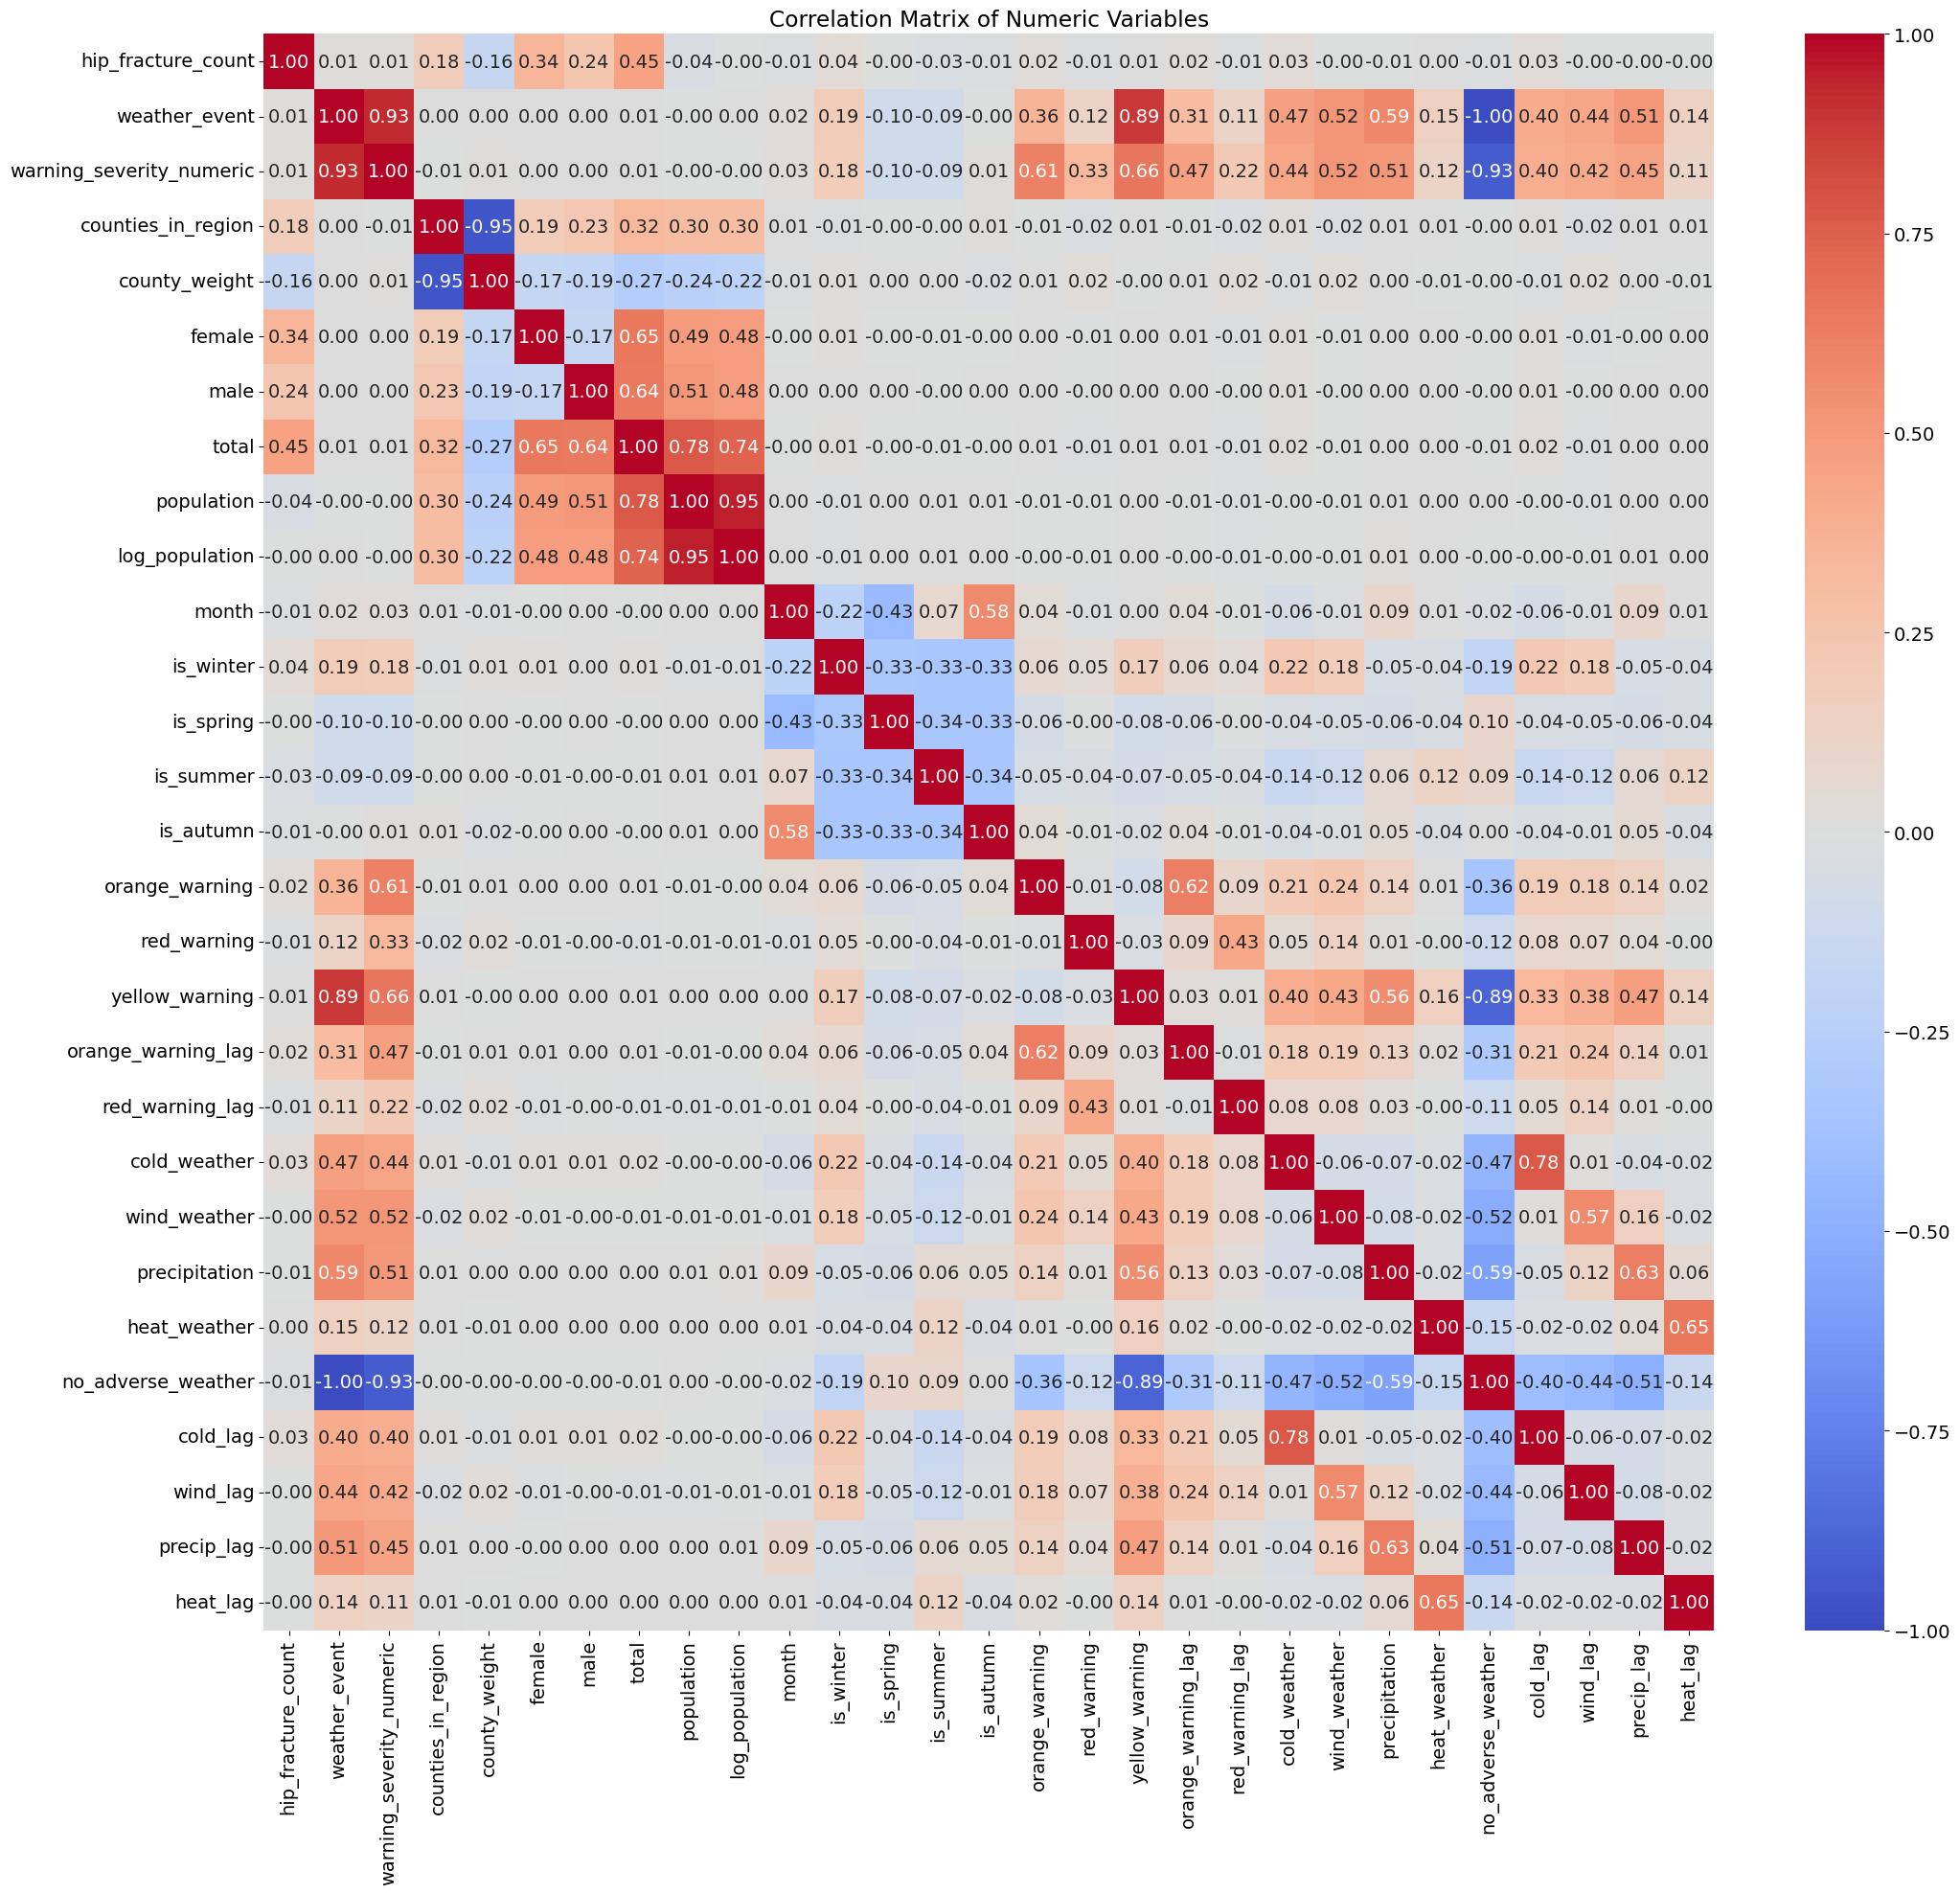

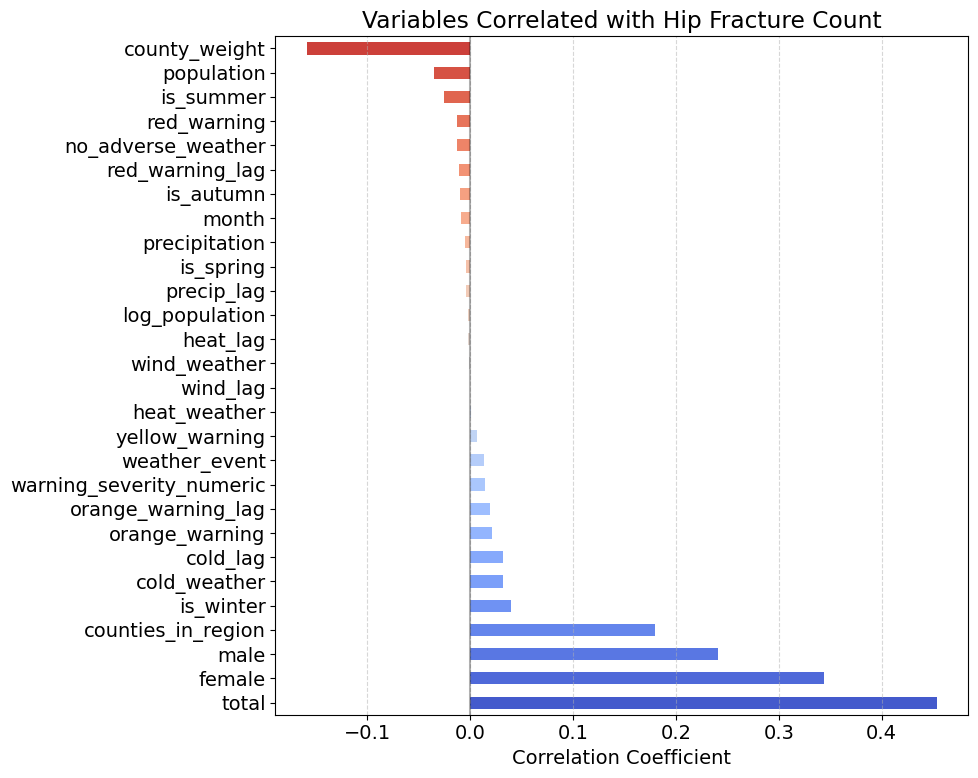

<Figure size 1500x1000 with 0 Axes>

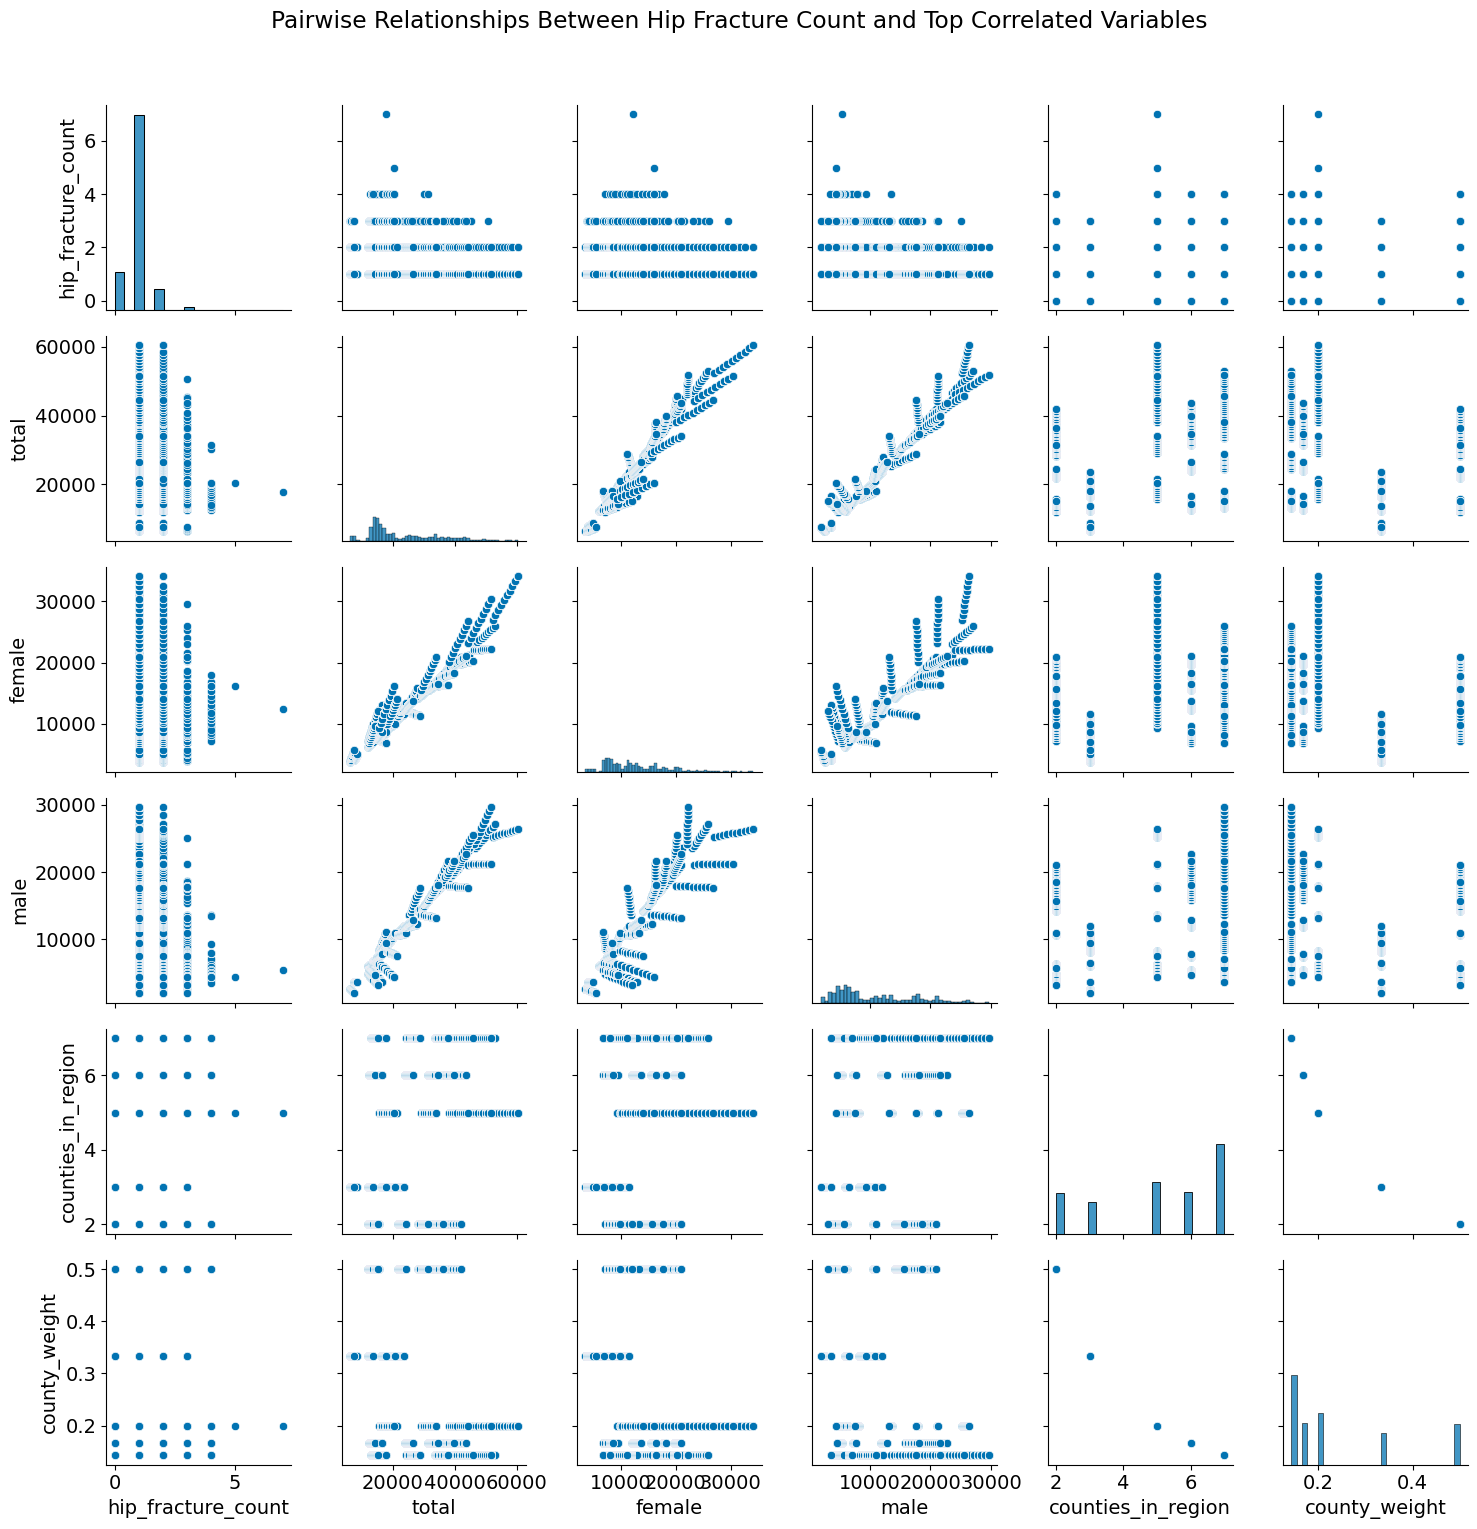

In [65]:
import matplotlib.pyplot as plt 
numeric_cols = df_final_expanded.select_dtypes(include=[np.number]).columns.tolist()

# Make sure 'hip_fracture_count' is included
if 'hip_fracture_count' not in numeric_cols:
    print("Warning: hip_fracture_count not found in numeric columns")
else:
    # Create a correlation matrix
    corr_matrix = df_final_expanded[numeric_cols].corr(method='pearson')
    
    # Sort with hip_fracture_count
    hip_correlations = corr_matrix['hip_fracture_count'].sort_values(ascending=False)
    print("Correlations with hip_fracture_count:")
    print(hip_correlations)
    
    # Plot heatmap
    plt.figure(figsize=(22, 20))
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
    plt.title('Correlation Matrix of Numeric Variables')
    plt.tight_layout()
    plt.show()
    
    # Create a bar plot of correlations with hip_fracture_count
    plt.figure(figsize=(10, 8))
    hip_correlations.drop('hip_fracture_count').plot(kind='barh', color=sns.color_palette("coolwarm", len(hip_correlations)))
    plt.title('Variables Correlated with Hip Fracture Count')
    plt.xlabel('Correlation Coefficient')
    plt.axvline(x=0, color='black', linestyle='-', alpha=0.3)
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    
    # Optional: Create pairplots for top correlated variables
    top_correlated = hip_correlations.drop('hip_fracture_count').abs().nlargest(5).index.tolist()
    top_vars = ['hip_fracture_count'] + top_correlated
    
    plt.figure(figsize=(15, 10))
    sns.pairplot(df_final[top_vars], height=2.5)
    plt.suptitle('Pairwise Relationships Between Hip Fracture Count and Top Correlated Variables', y=1.02)
    plt.tight_layout()
    plt.show()

### Step 8.2: Save complete final merged and aggregated dataset.

In [66]:
df_final_expanded.to_csv('/home/paulharford/college/project/project_data/processed/WEATHERED_merged_v2.csv', index=False)

### Step 9: Poisson Modeling

### Step 9.1: Create DF with Incidence Rate Ratios (IRR) with 95% Confidence Intervals: 

FITTING POISSON MODEL (BASELINE)

Poisson Dispersion parameter: 0.9118
Interpretation: Mild underdispersion

Cameron-Trivedi test: statistic = 85.7812, p-value = 0.0000
Significant evidence against equidispersion at 5% level

RESIDUAL DIAGNOSTICS:
----------------------------------------
Pearson residuals - Mean: 0.1083, Std: 1.1737
Ljung-Box test p-value (lag 1): 0.0000

Poisson Model Summary:
                 Generalized Linear Model Regression Results                  
Dep. Variable:     hip_fracture_count   No. Observations:                97119
Model:                            GLM   Df Residuals:                    97103
Model Family:                 Poisson   Df Model:                           15
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -76924.
Date:                Fri, 01 Aug 2025   Deviance:                       88534.
Time:                        10:48:42   Pearson c

/tmp/ipykernel_58266/1386251578.py:121: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  gp_alpha = gp_results.params[-1]



GP alpha parameter: -0.0078
Negative alpha confirms underdispersion

Generalized Poisson Model Summary:
                    GeneralizedPoisson Regression Results                     
Dep. Variable:                      y   No. Observations:                97119
Model:             GeneralizedPoisson   Df Residuals:                    97103
Method:                           MLE   Df Model:                           15
Date:                Fri, 01 Aug 2025   Pseudo R-squ.:                 0.02878
Time:                        10:48:43   Log-Likelihood:                -76890.
converged:                       True   LL-Null:                       -79168.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                                                                                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------

/home/paulharford/anaconda3/envs/msc/lib/python3.12/site-packages/statsmodels/base/model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '
/home/paulharford/anaconda3/envs/msc/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "



Negative Binomial Model Summary:


/home/paulharford/anaconda3/envs/msc/lib/python3.12/site-packages/statsmodels/base/model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '
/home/paulharford/anaconda3/envs/msc/lib/python3.12/site-packages/statsmodels/base/model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '


                     NegativeBinomial Regression Results                      
Dep. Variable:     hip_fracture_count   No. Observations:                97119
Model:               NegativeBinomial   Df Residuals:                    97103
Method:                           MLE   Df Model:                           15
Date:                Fri, 01 Aug 2025   Pseudo R-squ.:                 0.02862
Time:                        10:48:46   Log-Likelihood:                -76924.
converged:                      False   LL-Null:                       -79190.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                                                                                                  coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

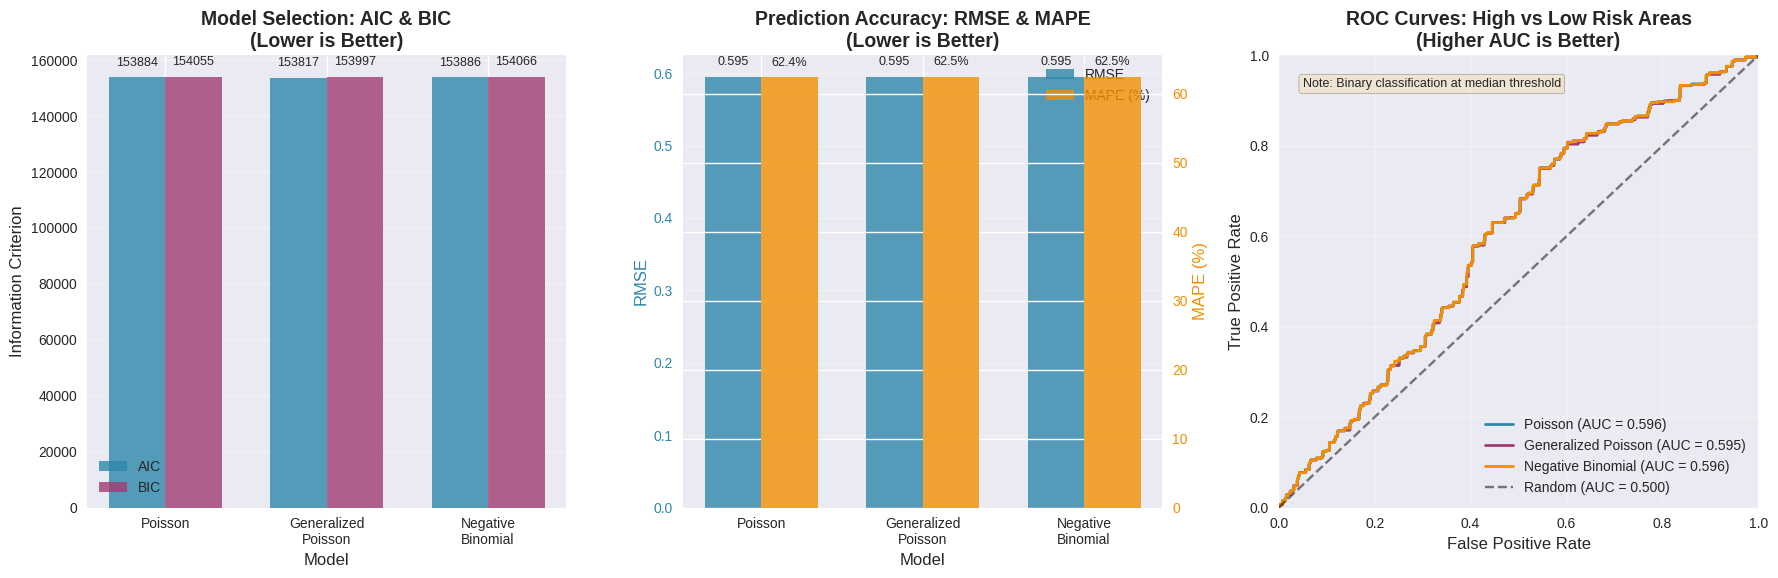


COMPREHENSIVE MODEL EVALUATION SUMMARY
              Model      AIC      BIC  RMSE   MAE  MAPE AUROC Within ±1 Within ±2 Pseudo R² Dispersion
            Poisson 153884.0 154054.7 0.595 0.465 62.4% 0.596     94.5%     99.6%     0.029      0.912
Generalized Poisson 153817.3 153997.5 0.595 0.465 62.5% 0.595     94.5%     99.6%     0.029        NaN
  Negative Binomial 153886.1 154066.3 0.595 0.465 62.5% 0.596     94.5%     99.6%     0.029        NaN

KEY INSIGHTS:

Best Model by Metric:
  AIC: Generalized Poisson
  BIC: Generalized Poisson
  RMSE: Generalized Poisson
  MAE: Negative Binomial
  MAPE: Poisson
  Auroc: Negative Binomial
  Within 1: Poisson
  Within 2: Poisson

Goodness-of-Fit Tests:
  Poisson: Pearson χ² p-value = 0.0000 (poor fit)
  Generalized Poisson: Pearson χ² p-value = 0.0000 (poor fit)
  Negative Binomial: Pearson χ² p-value = 0.0000 (poor fit)

INCIDENCE RATE RATIOS (IRR) FOR POISSON MODEL

IRRs with 95% Confidence Intervals:
                                        

In [67]:
# Imports
import statsmodels.api as sm
import statsmodels.formula.api as smf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import patsy
from statsmodels.discrete.discrete_model import GeneralizedPoisson, NegativeBinomial, Poisson
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from statsmodels.stats.diagnostic import acorr_ljungbox

# Set random seed for reproducibility
np.random.seed(42)

# Set plotting style for academic presentation
if 'seaborn-v0_8' in plt.style.available:
    plt.style.use('seaborn-v0_8')
elif 'seaborn' in plt.style.available:
    plt.style.use('seaborn')
else:
    plt.style.use('default')

# Define the model formula
formula = """
hip_fracture_count ~ 
C(weather_event, Treatment(reference=0)) +
C(warning_severity_numeric, Treatment(reference=0)) +
C(gender, Treatment(reference='Female')) +
county_weight + 
C(region, Treatment(reference='HSE South West')):C(weather_event, Treatment(reference=0)) +
C(gender, Treatment(reference='Female')):C(weather_event, Treatment(reference=0))
"""

# Define the offset
offset = df_final_expanded["log_population"]

# Prepare design matrices for later use
y, X = patsy.dmatrices(formula, data=df_final_expanded, return_type='dataframe')

### 1. Fit Poisson Model (Baseline)
print("="*60)
print("FITTING POISSON MODEL (BASELINE)")
print("="*60)

poisson_model = smf.glm(
    formula=formula, 
    data=df_final_expanded, 
    family=sm.families.Poisson(), 
    offset=offset
)
poisson_results = poisson_model.fit()

# Dispersion estimate and formal test
dispersion = poisson_results.deviance / poisson_results.df_resid
print(f"\nPoisson Dispersion parameter: {dispersion:.4f}")

# Interpret dispersion
if dispersion < 0.85:
    disp_interpretation = "Strong underdispersion"
elif dispersion < 0.95:
    disp_interpretation = "Mild underdispersion"
elif dispersion > 1.15:
    disp_interpretation = "Overdispersion"
else:
    disp_interpretation = "Approximate equidispersion"
print(f"Interpretation: {disp_interpretation}")

# Cameron & Trivedi dispersion test
def dispersion_test(model):
    """
    Cameron & Trivedi (1990) dispersion test
    H0: Equidispersion (var = mean)
    H1: Over/underdispersion
    """
    y = model.model.endog
    mu = model.fittedvalues
    
    # Correct auxiliary regression
    aux = ((y - mu)**2 - mu) / mu
    test_stat = np.sum(aux) / np.sqrt(2 * model.nobs)
    p_value = 2 * (1 - stats.norm.cdf(np.abs(test_stat)))
    
    return test_stat, p_value

test_stat, p_val = dispersion_test(poisson_results)
print(f"\nCameron-Trivedi test: statistic = {test_stat:.4f}, p-value = {p_val:.4f}")
if p_val < 0.05:
    print("Significant evidence against equidispersion at 5% level")

# Residual diagnostics
print("\nRESIDUAL DIAGNOSTICS:")
print("-" * 40)
pearson_resid = poisson_results.resid_pearson
print(f"Pearson residuals - Mean: {np.mean(pearson_resid):.4f}, Std: {np.std(pearson_resid):.4f}")

# Check for autocorrelation in residuals
ljung_box = acorr_ljungbox(pearson_resid, lags=10, return_df=True)
print(f"Ljung-Box test p-value (lag 1): {ljung_box['lb_pvalue'].iloc[0]:.4f}")
if ljung_box['lb_pvalue'].iloc[0] < 0.05:
    print("Warning: Significant autocorrelation detected in residuals")

print("\nPoisson Model Summary:")
print(poisson_results.summary())

### Generalized Poisson Model (For Underdispersion)
print("\n" + "="*60)
print("FITTING GENERALIZED POISSON MODEL (FOR UNDERDISPERSION)")
print("="*60)

# Convert y to 1D array
y_array = np.asarray(y).flatten()

try:
    gp_model = GeneralizedPoisson(endog=y_array, exog=X, offset=offset)
    gp_results = gp_model.fit(maxiter=1000, disp=False)
    
    # Extract alpha parameter
    gp_alpha = gp_results.params[-1]
    print(f"\nGP alpha parameter: {gp_alpha:.4f}")
    if gp_alpha < 0:
        print("Negative alpha confirms underdispersion")
    elif gp_alpha > 0:
        print("Positive alpha indicates overdispersion")
    
    print("\nGeneralized Poisson Model Summary:")
    print(gp_results.summary())
    gp_fitted = True
except Exception as e:
    print(f"\nGeneralized Poisson model failed: {e}")
    gp_fitted = False

### Negative Binomial Model (For Comparison)
print("\n" + "="*60)
print("FITTING NEGATIVE BINOMIAL MODEL (FOR COMPARISON)")
print("="*60)

try:
    nb_model = smf.negativebinomial(
        formula=formula, 
        data=df_final_expanded, 
        offset=offset
    )
    nb_results = nb_model.fit(disp=False)
    
    print("\nNegative Binomial Model Summary:")
    print(nb_results.summary())
    nb_fitted = True
except Exception as e:
    print(f"\nNegative Binomial model failed (expected for underdispersed data): {e}")
    nb_fitted = False

# Define evaluation functions
def calculate_aic_bic(model):
    """Calculate AIC and BIC for fitted model"""
    n = model.nobs
    k = len(model.params)  # Number of parameters
    log_lik = model.llf
    
    aic = 2 * k - 2 * log_lik
    bic = k * np.log(n) - 2 * log_lik
    
    return aic, bic

def calculate_prediction_metrics(y_true, y_pred):
    """Calculate various prediction metrics"""
    # Flatten arrays if needed
    y_true = np.asarray(y_true).flatten()
    y_pred = np.asarray(y_pred).flatten()
    
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    
    # MAPE protection against division by zero
    mask = y_true != 0
    zero_count = np.sum(~mask)
    if zero_count > 0 and zero_count < len(y_true) * 0.9:  # Only warn if less than 90% zeros
        print(f"Note: {zero_count} zero counts excluded from MAPE calculation")
    
    if np.sum(mask) > 0:
        mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    else:
        mape = np.nan
    
    # Additional metrics
    residuals = y_true - y_pred
    within_1 = np.sum(np.abs(residuals) <= 1) / len(residuals) * 100
    within_2 = np.sum(np.abs(residuals) <= 2) / len(residuals) * 100
    
    # Pearson chi-square statistic
    pearson_chi2 = np.sum((y_true - y_pred)**2 / y_pred)
    pearson_chi2_pvalue = 1 - stats.chi2.cdf(pearson_chi2, len(y_true) - len(X.columns))
    
    return {
        'mse': mse,
        'rmse': rmse,
        'mae': mae,
        'mape': mape,
        'within_1': within_1,
        'within_2': within_2,
        'residuals': residuals,
        'pearson_chi2': pearson_chi2,
        'pearson_chi2_pvalue': pearson_chi2_pvalue
    }

def calculate_auroc_for_count_models(y_true, y_pred, threshold=None):
    # Flatten arrays
    y_true = np.asarray(y_true).flatten()
    y_pred = np.asarray(y_pred).flatten()
    
    if threshold is None:
        threshold = np.median(y_true)  # Use true values for threshold
    
    # Convert to binary: high risk (1) vs low risk (0)
    y_true_binary = (y_true > threshold).astype(int)
    
    # Use predictions directly as scores for ROC curve
    try:
        auroc = roc_auc_score(y_true_binary, y_pred)
        fpr, tpr, _ = roc_curve(y_true_binary, y_pred)
        return auroc, fpr, tpr
    except Exception as e:
        print(f"AUROC calculation failed: {e}")
        return np.nan, None, None

def calculate_pseudo_r2(model, y, X, offset, model_type='glm'):
    """Calculate McFadden's pseudo R-squared"""
    # Null model with intercept only
    if model_type == 'glm':
        null_model = sm.GLM(y, np.ones((len(y), 1)), 
                            family=model.family, 
                            offset=offset)
    else:  # For negative binomial and other models
        null_model = sm.GLM(y, np.ones((len(y), 1)), 
                            family=sm.families.Poisson(), 
                            offset=offset)
    null_results = null_model.fit()
    
    mcfadden_r2 = 1 - (model.llf / null_results.llf)
    return mcfadden_r2

# Evaluate fitted models
print("\n" + "="*60)
print("MODEL EVALUATION")
print("="*60)

results = {}

# Extract predictions
y_true = np.asarray(y).flatten()

# Evaluate Poisson
y_pred_poisson = poisson_results.predict()
aic_p, bic_p = calculate_aic_bic(poisson_results)
metrics_p = calculate_prediction_metrics(y_true, y_pred_poisson)
auroc_p, fpr_p, tpr_p = calculate_auroc_for_count_models(y_true, y_pred_poisson)
pseudo_r2_p = calculate_pseudo_r2(poisson_results, y, X, offset, model_type='glm')

results['Poisson'] = {
    'aic': aic_p,
    'bic': bic_p,
    'log_likelihood': poisson_results.llf,
    **metrics_p,
    'auroc': auroc_p,
    'fpr': fpr_p,
    'tpr': tpr_p,
    'dispersion': dispersion,
    'pseudo_r2': pseudo_r2_p
}

# Evaluate Generalized Poisson
if gp_fitted:
    y_pred_gp = gp_results.predict()
    aic_gp, bic_gp = calculate_aic_bic(gp_results)
    metrics_gp = calculate_prediction_metrics(y_true, y_pred_gp)
    auroc_gp, fpr_gp, tpr_gp = calculate_auroc_for_count_models(y_true, y_pred_gp)
    try:
        pseudo_r2_gp = calculate_pseudo_r2(gp_results, y, X, offset, model_type='other')
    except:
        pseudo_r2_gp = np.nan
    
    results['Generalized Poisson'] = {
        'aic': aic_gp,
        'bic': bic_gp,
        'log_likelihood': gp_results.llf,
        **metrics_gp,
        'auroc': auroc_gp,
        'fpr': fpr_gp,
        'tpr': tpr_gp,
        'alpha': gp_alpha,
        'pseudo_r2': pseudo_r2_gp
    }

# Evaluate Negative Binomial
if nb_fitted:
    y_pred_nb = nb_results.predict()
    aic_nb, bic_nb = calculate_aic_bic(nb_results)
    metrics_nb = calculate_prediction_metrics(y_true, y_pred_nb)
    auroc_nb, fpr_nb, tpr_nb = calculate_auroc_for_count_models(y_true, y_pred_nb)
    pseudo_r2_nb = calculate_pseudo_r2(nb_results, y, X, offset, model_type='nb')
    
    results['Negative Binomial'] = {
        'aic': aic_nb,
        'bic': bic_nb,
        'log_likelihood': nb_results.llf,
        **metrics_nb,
        'auroc': auroc_nb,
        'fpr': fpr_nb,
        'tpr': tpr_nb,
        'alpha': nb_results.scale if hasattr(nb_results, 'scale') else np.nan,
        'pseudo_r2': pseudo_r2_nb
    }

# Create evaluation plots
def create_evaluation_plots(results):
    """Create three separate plots for model evaluation"""
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    models = list(results.keys())
    colors = ['#2E86AB', '#A23B72', '#F18F01']
    
    # Plot 1: AIC/BIC Comparison
    ax1 = axes[0]
    x = np.arange(len(models))
    width = 0.35
    
    aic_values = [results[m]['aic'] for m in models]
    bic_values = [results[m]['bic'] for m in models]
    
    bars1 = ax1.bar(x - width/2, aic_values, width, label='AIC', color=colors[0], alpha=0.8)
    bars2 = ax1.bar(x + width/2, bic_values, width, label='BIC', color=colors[1], alpha=0.8)
    
    ax1.set_xlabel('Model', fontsize=12)
    ax1.set_ylabel('Information Criterion', fontsize=12)
    ax1.set_title('Model Selection: AIC & BIC\n(Lower is Better)', fontsize=14, fontweight='bold')
    ax1.set_xticks(x)
    ax1.set_xticklabels([m.replace(' ', '\n') for m in models])
    ax1.legend()
    ax1.grid(True, alpha=0.3, axis='y')
    
    # Add values on bars
    for i, (aic, bic) in enumerate(zip(aic_values, bic_values)):
        ax1.text(i - width/2, aic + max(aic_values)*0.02, f'{aic:.0f}', 
                ha='center', va='bottom', fontsize=9)
        ax1.text(i + width/2, bic + max(bic_values)*0.02, f'{bic:.0f}', 
                ha='center', va='bottom', fontsize=9)
    
    # Plot 2: RMSE & MAPE Comparison
    ax2 = axes[1]
    
    rmse_values = [results[m]['rmse'] for m in models]
    mape_values = [results[m]['mape'] for m in models]
    ax2_twin = ax2.twinx()
    
    bars1 = ax2.bar(x - width/2, rmse_values, width, label='RMSE', color=colors[0], alpha=0.8)
    bars2 = ax2_twin.bar(x + width/2, mape_values, width, label='MAPE (%)', color=colors[2], alpha=0.8)
    
    ax2.set_xlabel('Model', fontsize=12)
    ax2.set_ylabel('RMSE', fontsize=12, color=colors[0])
    ax2_twin.set_ylabel('MAPE (%)', fontsize=12, color=colors[2])
    ax2.set_title('Prediction Accuracy: RMSE & MAPE\n(Lower is Better)', fontsize=14, fontweight='bold')
    ax2.set_xticks(x)
    ax2.set_xticklabels([m.replace(' ', '\n') for m in models])
    ax2.grid(True, alpha=0.3, axis='y')
    
    # Color the y-axis labels
    ax2.tick_params(axis='y', labelcolor=colors[0])
    ax2_twin.tick_params(axis='y', labelcolor=colors[2])
    
    # Add values on bars
    for i, (rmse, mape) in enumerate(zip(rmse_values, mape_values)):
        ax2.text(i - width/2, rmse + max(rmse_values)*0.02, f'{rmse:.3f}', 
                ha='center', va='bottom', fontsize=9)
        ax2_twin.text(i + width/2, mape + max(mape_values)*0.02, f'{mape:.1f}%', 
                     ha='center', va='bottom', fontsize=9)
    
    # Add legends
    lines1, labels1 = ax2.get_legend_handles_labels()
    lines2, labels2 = ax2_twin.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
    
    # Plot 3 AUROC Comparison
    ax3 = axes[2]
    
    # Plot ROC curves
    for i, model in enumerate(models):
        if results[model]['fpr'] is not None and results[model]['tpr'] is not None:
            ax3.plot(results[model]['fpr'], results[model]['tpr'], 
                    label=f"{model} (AUC = {results[model]['auroc']:.3f})",
                    color=colors[i], linewidth=2)
    
    # Plot diagonal reference line
    ax3.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random (AUC = 0.500)')
    
    ax3.set_xlabel('False Positive Rate', fontsize=12)
    ax3.set_ylabel('True Positive Rate', fontsize=12)
    ax3.set_title('ROC Curves: High vs Low Risk Areas\n(Higher AUC is Better)', fontsize=14, fontweight='bold')
    ax3.text(0.05, 0.95, 'Note: Binary classification at median threshold', 
             transform=ax3.transAxes, fontsize=9, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    ax3.legend(loc='lower right')
    ax3.grid(True, alpha=0.3)
    ax3.set_xlim([0, 1])
    ax3.set_ylim([0, 1])
    
    plt.tight_layout()
    return fig

def create_summary_table(results):
    """Create a comprehensive summary table"""
    
    summary_data = []
    for model, metrics in results.items():
        row_data = {
            'Model': model,
            'AIC': f"{metrics['aic']:.1f}",
            'BIC': f"{metrics['bic']:.1f}",
            'RMSE': f"{metrics['rmse']:.3f}",
            'MAE': f"{metrics['mae']:.3f}",
            'MAPE': f"{metrics['mape']:.1f}%",
            'AUROC': f"{metrics['auroc']:.3f}" if not np.isnan(metrics['auroc']) else "N/A",
            'Within ±1': f"{metrics['within_1']:.1f}%",
            'Within ±2': f"{metrics['within_2']:.1f}%"
        }
        
        # Add model-specific metrics
        if 'pseudo_r2' in metrics:
            row_data['Pseudo R²'] = f"{metrics['pseudo_r2']:.3f}"
        if 'dispersion' in metrics:
            row_data['Dispersion'] = f"{metrics['dispersion']:.3f}"
        
        summary_data.append(row_data)
    
    df_summary = pd.DataFrame(summary_data)
    
    # Print formatted table
    print("\n" + "="*80)
    print("COMPREHENSIVE MODEL EVALUATION SUMMARY")
    print("="*80)
    print(df_summary.to_string(index=False))
    print("="*80)
    
    # insights
    print("\nKEY INSIGHTS:")
    
    # Best model by each metric
    print("\nBest Model by Metric:")
    
    # For metrics to minimize
    for metric in ['AIC', 'BIC', 'RMSE', 'MAE', 'MAPE']:
        values = []
        for m in results.keys():
            try:
                val = float(results[m][metric.lower()].rstrip('%') if isinstance(results[m][metric.lower()], str) else results[m][metric.lower()])
                values.append(val)
            except:
                values.append(np.inf)
        
        if len(values) > 0 and not all(np.isinf(values)):
            best_idx = np.argmin(values)
            best_model = list(results.keys())[best_idx]
            print(f"  {metric}: {best_model}")
    
    # For metrics to maximize
    for metric in ['AUROC', 'within_1', 'within_2']:
        values = []
        for m in results.keys():
            try:
                val = results[m][metric.lower()]
                values.append(val if not np.isnan(val) else -np.inf)
            except:
                values.append(-np.inf)
        
        if len(values) > 0 and not all(np.isinf(values)):
            best_idx = np.argmax(values)
            best_model = list(results.keys())[best_idx]
            print(f"  {metric.replace('_', ' ').title()}: {best_model}")
    
    # Report goodness-of-fit - this does not work correctly - do not use 
    print("\nGoodness-of-Fit Tests:")
    for model in results.keys():
        if 'pearson_chi2_pvalue' in results[model]:
            p_val = results[model]['pearson_chi2_pvalue']
            print(f"  {model}: Pearson χ² p-value = {p_val:.4f}", end="")
            if p_val < 0.05:
                print(" (poor fit)")
            else:
                print(" (adequate fit)")
    
    return df_summary

# Create the plots
print("\nCreating evaluation plots...")
fig = create_evaluation_plots(results)

# Save the figure 
fig.savefig('hip_fracture_model_evaluation_plots.png', dpi=300, bbox_inches='tight')
fig.savefig('hip_fracture_model_evaluation_plots.pdf', bbox_inches='tight')  # PDF for LaTeX
print("Plots saved as 'hip_fracture_model_evaluation_plots.png' and '.pdf'")

plt.show()

# Create summary table
summary = create_summary_table(results)

# Print IRR table
print("\n" + "="*80)
print("INCIDENCE RATE RATIOS (IRR) FOR POISSON MODEL")
print("="*80)
print("\nIRRs with 95% Confidence Intervals:")
params = poisson_results.params
conf = poisson_results.conf_int()

# Create a DataFrame for better formatting
irr_df = pd.DataFrame({
    'IRR': np.exp(params),
    'Lower CI': np.exp(conf[0]),
    'Upper CI': np.exp(conf[1]),
    'p-value': poisson_results.pvalues
})
print(irr_df)

# Save results for later use
model_comparison_results = {
    'results': results,
    'summary': summary,
    'models': {
        'poisson': poisson_results,
        'generalized_poisson': gp_results if gp_fitted else None,
        'negative_binomial': nb_results if nb_fitted else None
    }
}

In [68]:
# After fitting the Poisson model
print("\nIncidence Rate Ratios (IRR) with 95% Confidence Intervals:")
params = poisson_results.params
conf = poisson_results.conf_int()

# Create a DataFrame for better formatting
irr_df = pd.DataFrame({
    'IRR': np.exp(params),
    'Lower CI': np.exp(conf[0]),
    'Upper CI': np.exp(conf[1]),
    'p-value': poisson_results.pvalues
})

print(irr_df)


Incidence Rate Ratios (IRR) with 95% Confidence Intervals:
                                                         IRR  Lower CI  \
Intercept                                           0.000110  0.000107   
C(weather_event, Treatment(reference=0))[T.1.0]     0.992064  0.925529   
C(warning_severity_numeric, Treatment(reference...  1.047143  0.987929   
C(warning_severity_numeric, Treatment(reference...  1.253205  1.172395   
C(warning_severity_numeric, Treatment(reference...  0.755982  0.647937   
C(gender, Treatment(reference='Female'))[T.Male]    0.608143  0.593034   
C(region, Treatment(reference='HSE South West')...  0.390688  0.376547   
C(region, Treatment(reference='HSE South West')...  0.666945  0.644541   
C(region, Treatment(reference='HSE South West')...  0.639680  0.617698   
C(region, Treatment(reference='HSE South West')...  0.441098  0.420756   
C(region, Treatment(reference='HSE South West')...  0.507667  0.489159   
C(region, Treatment(reference='HSE South West')...  